# Project summary
> Can EEG activity in a specific time window predict the participant’s perceived emotion, separately within each ambiguity level?


1. Decoding fear or happy with binary classification within each ambiguity level

2. Cross-decoding to test generalization of ambiguity level

    a. Training emotion classification using low ambiguity trials only

    b. Apply this trained model to high ambiguity trials.

    c. Evaluate the accuracy. If accuracy is still high, the emotion code is stable.


In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score

import mne
import numpy as np
import os
import re
import scipy.io as sio
from collections import defaultdict, deque
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import balanced_accuracy_score
from sklearn.preprocessing import StandardScaler


from sklearn.pipeline import Pipeline
from mne.decoding import CSP
from sklearn.svm import SVC
from mne.preprocessing import ICA
from sklearn.decomposition import PCA

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.base import clone
from mne.time_frequency import tfr_morlet
from sklearn.model_selection import RepeatedStratifiedKFold

`pip install pandas numpy scikit-learn matplotlib seaborn openpyxl`

`pip install mne pandas scikit-learn openpyxl matplotlib`

In [2]:
import pandas as pd
import numpy as np

path = "03 EEG Data and Code/FearHappyJudgment_Behavior and LPP.xlsx"

df = pd.read_excel(path).iloc[:, :5]

df.head()

,subID,codeL,vResp,RT,LPP
0,1,2,0,1143,1.747909
1,1,3,0,1233,5.892490
2,1,2,0,1195,4.262819
3,1,6,1,1115,2.531541
4,1,4,0,1214,-2.017248


`subID`: participant

`codeL`: morph level (1–7)

`vResp`: participant decision

`RT`: response time

`LPP`: EEG amplitude

# Check Behavior and LPP data
Morph level (1 happy → 7 fear)

- low ambiguity      : 1,7

- medium ambiguity   : 2,3,5,6

- high ambiguity     : 4

,subID,codeL,vResp,RT,LPP,ambiguity
0,1,2,0,1143,1.747909,medium
1,1,3,0,1233,5.892490,medium
2,1,2,0,1195,4.262819,medium
3,1,6,1,1115,2.531541,medium
4,1,4,0,1214,-2.017248,high


ambiguity
high       565
low       1137
medium    2301
dtype: int64

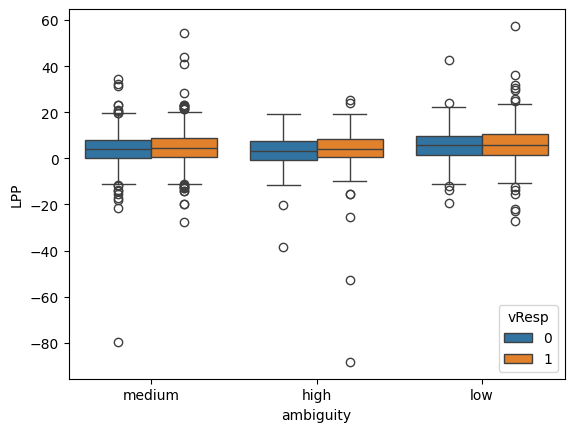

In [3]:
# Bin the codeL values into low, medium, and high ambiguity
# Check the distribution of codeL values
def ambiguity_bin(code):
    if code in [1,7]:
        return "low"
    if code in [2,3,5,6]:
        return "medium"
    if code == 4:
        return "high"

df["ambiguity"] = df["codeL"].apply(ambiguity_bin)
display(df.head())
display(df.groupby("ambiguity").size())

sns.boxplot(data=df, x="ambiguity", y="LPP", hue="vResp")
plt.show()

# Preprocessing
Use **perceived valence** from `vResp (fear=1, happy=0)` in behaviorData.mat instead of objective EEG-side valence.

E.g. EEG tags `B7(17)` are decoded as `codeI=1`(face ID) and `codeL=7` (face level), then matched to behavior trials by `codeI, codeL` using FIFO order.

All morph levels 1–7 are now included in training and evaluation.

## 1. Load EEG subject

In [2]:
eeg_path = "03 EEG Data and Code/MainTask_ShortEpoch"
# eeg_path = "03 EEG Data and Code/MainTask_LongEpoch"
behavior_mat_path = "02 Behavioral Data and Code/behaviorData.mat"

In [30]:
file = os.path.join(eeg_path, "sub1ar.set")
epochs = mne.io.read_epochs_eeglab(file)
epochs

# file = os.path.join(eeg_path, "sub1.set")
# epochs = mne.io.read_epochs_eeglab(file, uint16_codec='utf-8')
# epochs


Extracting parameters from /Users/grantsfolder/Desktop/COGS 189/COGS189_Face_emotion_EEG/03 EEG Data and Code/MainTask_ShortEpoch/sub1ar.set...
Not setting metadata
203 matching events found
No baseline correction applied
0 projection items activated
Ready.


<EpochsEEGLAB | 203 events (all good), -0.2 – 0.798 s (baseline off), ~25.6 MiB, data loaded,
 'B1(31)': 8
 'B2(32)': 9
 'B3(33)': 7
 'B5(45)': 8
 'B2(22)': 9
 'B6(46)': 7
 'B4(24)': 7
 'B7(37)': 8
 'B4(44)': 7
 'B5(35)': 6
 and 18 more events ...>

## 2. Extract Morph Levels

In [31]:
# Parse EEG event labels to extract codeI (face ID) and codeL (morph level) per trial
# Example: B7(17) -> codeI=1, codeL=7

inv_event_id = {v: k for k, v in epochs.event_id.items()}
events = epochs.events[:, 2]
event_names = [inv_event_id[e] for e in events]

event_codeI = []
event_codeL = []

for name in event_names:
    m = re.search(r"\((\d+)(\d)\)", name)
    if m is None:
        raise ValueError(f"Cannot parse event name: {name}")
    code_i = int(m.group(1))
    code_l = int(m.group(2))
    event_codeI.append(code_i)
    event_codeL.append(code_l)

event_codeI = np.array(event_codeI)
morph_levels = np.array(event_codeL)

print("Unique morph levels in EEG:", np.unique(morph_levels, return_counts=True))
print("Unique face IDs in EEG:", np.unique(event_codeI, return_counts=True))

Unique morph levels in EEG: (array([1, 2, 3, 4, 5, 6, 7]), array([29, 32, 30, 28, 30, 24, 30]))
Unique face IDs in EEG: (array([1, 2, 3, 4]), array([51, 48, 51, 53]))


In [ ]:
# Load perceived responses from behaviorData.mat and align to EEG events
mat = sio.loadmat(behavior_mat_path, struct_as_record=False, squeeze_me=True)
eeg_data = mat["eegData"]

# Get subject number from EEG filename: sub1ar.set -> 1
sub_match = re.search(r"sub(\d+)", os.path.basename(file))
if sub_match is None:
    raise ValueError(f"Could not infer subject ID from filename: {file}")
sub_id = int(sub_match.group(1))

sub_beh = eeg_data[sub_id - 1]  # matlab is 1-indexed; python is 0-indexed
beh_codeI = np.asarray(sub_beh.codeI).astype(int)
beh_codeL = np.asarray(sub_beh.codeL).astype(int)
beh_vResp = np.asarray(sub_beh.vResp).astype(int)

print(f"Subject {sub_id}: behavior trials = {len(beh_vResp)}, EEG trials = {len(morph_levels)}")

# Build FIFO queues for perceived responses keyed by (codeI, codeL)
resp_queue = defaultdict(deque)
for ci, cl, vr in zip(beh_codeI, beh_codeL, beh_vResp):
    resp_queue[(ci, cl)].append(vr)

# Match each EEG trial to perceived response using codeI + codeL
matched_vResp = []
missing = 0
for ci, cl in zip(event_codeI, morph_levels):
    key = (int(ci), int(cl))
    if len(resp_queue[key]) == 0:
        matched_vResp.append(np.nan)
        missing += 1
    else:
        matched_vResp.append(resp_queue[key].popleft())

matched_vResp = np.asarray(matched_vResp, dtype=float)
print(f"Matched EEG trials: {np.sum(~np.isnan(matched_vResp))}/{len(matched_vResp)}")
print(f"Unmatched EEG trials: {missing}")

Subject 1: behavior trials = 252, EEG trials = 203
Matched EEG trials: 203/203
Unmatched EEG trials: 0


## 3. Extract emotion and ambiguity labels

In [33]:
# Keep only trials that were successfully matched to behavior data
valid_mask = ~np.isnan(matched_vResp)

epochs = epochs[valid_mask]
event_codeI = event_codeI[valid_mask]
morph_levels = morph_levels[valid_mask]
matched_vResp = matched_vResp[valid_mask].astype(int)

# Perceived valence label from behavior: 1 = fearful, 2 = happy
y = np.zeros(len(matched_vResp), dtype=int)
y[matched_vResp == 1] = 1   # fear = 1, happy = 0

print("Final trial count:", len(y))
print("Label counts (0=happy, 1=fear):", np.unique(y, return_counts=True))

Final trial count: 203
Label counts (0=happy, 1=fear): (array([0, 1]), array([113,  90]))


In [61]:
def ambiguity_bin(code):
    if code in [1, 7]:
        return "low"
    elif code in [2, 3, 5, 6]:
        return "medium"
    elif code == 4:
        return "high"
    return "unknown"

ambiguity = np.array([ambiguity_bin(c) for c in morph_levels])
ambiguity_count = np.unique(ambiguity, return_counts=True)
[(str(ambiguity_count[0][i]) + ": " + str(ambiguity_count[1][i])) for i in range(3)]

['high: 28', 'low: 59', 'medium: 116']

# Baseline

In [35]:
epochs_lpp = epochs.copy().crop(tmin=0.4, tmax=0.7)

X = epochs_lpp.get_data().mean(axis=2)   # trials × channels

# Standardize features
scaler = StandardScaler()
X = scaler.fit_transform(X)

In [36]:
def within_ambiguity(X, y, ambiguity, level):

    mask = ambiguity == level

    X_sub = X[mask]
    y_sub = y[mask]

    # Skip if only one class is present in this ambiguity bin
    if len(np.unique(y_sub)) < 2 or len(y_sub) < 10:
        return np.nan

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    scores = []

    for train, test in cv.split(X_sub, y_sub):

        model = LogisticRegression(max_iter=1000)
        model.fit(X_sub[train], y_sub[train])

        preds = model.predict(X_sub[test])
        acc = balanced_accuracy_score(y_sub[test], preds)

        scores.append(acc)

    return np.mean(scores)

for level in ["low", "medium", "high"]:
    acc = within_ambiguity(X, y, ambiguity, level)
    print(level, acc)

low 0.5266666666666666
medium 0.5303496503496504
high 0.4583333333333333


## Cross decoding

In [37]:
def cross_ambiguity(X, y, ambiguity, train_level, test_level):

    train_mask = ambiguity == train_level
    test_mask = ambiguity == test_level

    X_train = X[train_mask]
    y_train = y[train_mask]
    X_test = X[test_mask]
    y_test = y[test_mask]

    # Need both classes in training and test to compute meaningful balanced accuracy
    if len(np.unique(y_train)) < 2 or len(np.unique(y_test)) < 2:
        return np.nan

    model = LogisticRegression(max_iter=1000)

    model.fit(X_train, y_train)
    preds = model.predict(X_test)

    return balanced_accuracy_score(y_test, preds)

In [38]:
levels = ["low", "medium", "high"]

for train_level in levels:
    for test_level in levels:
        if train_level == test_level:
            continue
        score = cross_ambiguity(X, y, ambiguity, train_level, test_level)
        print(f"{train_level.capitalize()} → {test_level.capitalize()}: {score:.4f}")

Low → Medium: 0.5101
Low → High: 0.5833
Medium → Low: 0.4914
Medium → High: 0.6111
High → Low: 0.5580
High → Medium: 0.6087


# Advance model


In [82]:
# 1) Preprocessing: band-pass filter + ICA artifact removal
# Band-pass filter
epochs_filt = epochs.copy().filter(l_freq=1., h_freq=30., fir_design="firwin")

# ICA (fit on epoched data)
ica = ICA(n_components=5, random_state=42, max_iter="auto")
ica.fit(epochs_filt)

# Optional: if you have EOG channels, auto-detect and remove
try:
    eog_inds, _ = ica.find_bads_eog(epochs_filt)
    ica.exclude = eog_inds
except Exception:
    # If no EOG channels or detection fails, skip auto exclusion
    pass

# epochs_clean = ica.apply(epochs_filt.copy())

# 2) Morlet time-frequency decomposition (average=False)
freqs = np.arange(4, 31, 1)
cycles = freqs / 2.0
power = tfr_morlet(
    # epochs_clean,
    epochs_filt,
    freqs=freqs,
    n_cycles=cycles,
    average=False,
    return_itc=False,
    decim=1
)

# 3) Extract band power features (theta, alpha, beta)
bands = {
    "theta": (4, 8),
    "alpha": (8, 13),
    "beta": (13, 30),
}

# power.data shape: (n_epochs, n_channels, n_freqs, n_times)
# Average over time and frequencies within each band
band_features = []
for band_name, (fmin, fmax) in bands.items():
    f_mask = (power.freqs >= fmin) & (power.freqs <= fmax)
    band_pow = power.data[:, :, f_mask, :].mean(axis=3).mean(axis=2)  # epochs x channels
    band_features.append(band_pow)

# Feature dimension: n_channels * n_bands
X_feat = np.concatenate(band_features, axis=1)

print(f"Band-power feature matrix shape: {X_feat.shape} (trials × channels*bands)")

# 4) Classification pipeline: Scaler + PCA + SVM (with fixed hyperparameters)
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.9)),
    ("svm", SVC(kernel="rbf", C=1, gamma="scale"))
])

# 5) Within-ambiguity decoding with RepeatedStratifiedKFold and permutation testing
def decode_within_ambiguity_adv(X, y, ambiguity, level):
    """Decode within single ambiguity level using RepeatedStratifiedKFold."""
    mask = ambiguity == level
    X_sub = X[mask]
    y_sub = y[mask]

    if len(np.unique(y_sub)) < 2:
        return np.nan, np.nan

    cv = RepeatedStratifiedKFold(
        n_splits=5,
        n_repeats=20,
        random_state=42
    )

    scores = []

    for train_idx, test_idx in cv.split(X_sub, y_sub):
        pipeline.fit(X_sub[train_idx], y_sub[train_idx])
        preds = pipeline.predict(X_sub[test_idx])
        acc = balanced_accuracy_score(y_sub[test_idx], preds)
        scores.append(acc)

    return np.mean(scores), np.std(scores)

# 6) Permutation testing for statistical significance
from sklearn.model_selection import permutation_test_score

def permutation_test_adv(X, y, ambiguity, level):
    """Permutation test for within-ambiguity level."""
    mask = ambiguity == level
    X_sub = X[mask]
    y_sub = y[mask]

    score, perm_scores, pvalue = permutation_test_score(
        pipeline,
        X_sub,
        y_sub,
        cv=5,
        scoring="balanced_accuracy",
        n_permutations=1000,
        n_jobs=-1,
        random_state=42
    )

    return score, pvalue

# 7) Train within each ambiguity level
print("\n" + "=" * 70)
print("ADVANCED MODEL: WITHIN-AMBIGUITY DECODING (RepeatedStratifiedKFold)")
print("=" * 70)

levels = ["low", "medium", "high"]

for level in levels:
    mean_acc, std_acc = decode_within_ambiguity_adv(X_feat, y, ambiguity, level)
    score, pval = permutation_test_adv(X_feat, y, ambiguity, level)
    print(f"{level.upper():8s} → Mean={mean_acc:.3f} ± {std_acc:.3f}, Permutation p={pval:.4f}")

# 8) Cross-decoding across ambiguity levels
print("\n" + "=" * 70)
print("ADVANCED MODEL: CROSS-DECODING")
print("=" * 70)

def cross_decode_adv(X, y, ambiguity, train_level, test_level):
    """Direct cross-decoding between ambiguity levels."""
    train_mask = ambiguity == train_level
    test_mask = ambiguity == test_level

    X_train, y_train = X[train_mask], y[train_mask]
    X_test, y_test = X[test_mask], y[test_mask]

    if len(np.unique(y_train)) < 2 or len(np.unique(y_test)) < 2:
        return np.nan

    pipeline.fit(X_train, y_train)
    preds = pipeline.predict(X_test)

    return balanced_accuracy_score(y_test, preds)

for train_level in levels:
    for test_level in levels:
        if train_level == test_level:
            continue

        score = cross_decode_adv(X_feat, y, ambiguity, train_level, test_level)
        print(f"{train_level.upper()} → {test_level.upper()} = {score:.3f}")

Setting up band-pass filter from 1 - 30 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 30.00 Hz
- Upper transition bandwidth: 7.50 Hz (-6 dB cutoff frequency: 33.75 Hz)
- Filter length: 1651 samples (3.302 s)



/var/folders/bj/p5l9vvcj21nfh__sngfwhp3h0000gn/T/ipykernel_77360/921037139.py:3: RuntimeWarning: filter_length (1651) is longer than the signal (500), distortion is likely. Reduce filter length or filter a longer signal.
  epochs_filt = epochs.copy().filter(l_freq=1., h_freq=30., fir_design="firwin")


Fitting ICA to data using 33 channels (please be patient, this may take a while)
Selecting by number: 5 components
Fitting ICA took 0.5s.
NOTE: tfr_morlet() is a legacy function. New code should use .compute_tfr(method="morlet").
Band-power feature matrix shape: (203, 99) (trials × channels*bands)

ADVANCED MODEL: WITHIN-AMBIGUITY DECODING (RepeatedStratifiedKFold)
LOW      → Mean=0.497 ± 0.116, Permutation p=0.7642
MEDIUM   → Mean=0.549 ± 0.068, Permutation p=0.1399
HIGH     → Mean=0.463 ± 0.084, Permutation p=0.6324

ADVANCED MODEL: CROSS-DECODING
LOW → MEDIUM = 0.474
LOW → HIGH = 0.611
MEDIUM → LOW = 0.453
MEDIUM → HIGH = 0.461
HIGH → LOW = 0.500
HIGH → MEDIUM = 0.500


In [ ]:
LOW      → Mean=0.497 ± 0.116, Permutation p=0.7642
MEDIUM   → Mean=0.549 ± 0.068, Permutation p=0.1399
HIGH     → Mean=0.463 ± 0.084, Permutation p=0.6324

# Visualizations

In [46]:
# 1) Preprocessing: band-pass filter + baseline correction
epochs_filt = epochs.copy().filter(l_freq=0.1, h_freq=40.)
epochs_filt.apply_baseline((-0.2, 0))

Setting up band-pass filter from 0.1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.10
- Lower transition bandwidth: 0.10 Hz (-6 dB cutoff frequency: 0.05 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 16501 samples (33.002 s)



/var/folders/bj/p5l9vvcj21nfh__sngfwhp3h0000gn/T/ipykernel_77360/1490988338.py:2: RuntimeWarning: filter_length (16501) is longer than the signal (500), distortion is likely. Reduce filter length or filter a longer signal.
  epochs_filt = epochs.copy().filter(l_freq=0.1, h_freq=40.)


Applying baseline correction (mode: mean)


<EpochsEEGLAB | 203 events (all good), -0.2 – 0.798 s (baseline -0.2 – 0 s), ~25.6 MiB, data loaded,
 'B1(31)': 8
 'B2(32)': 9
 'B3(33)': 7
 'B5(45)': 8
 'B2(22)': 9
 'B6(46)': 7
 'B4(24)': 7
 'B7(37)': 8
 'B4(44)': 7
 'B5(35)': 6
 and 18 more events ...>

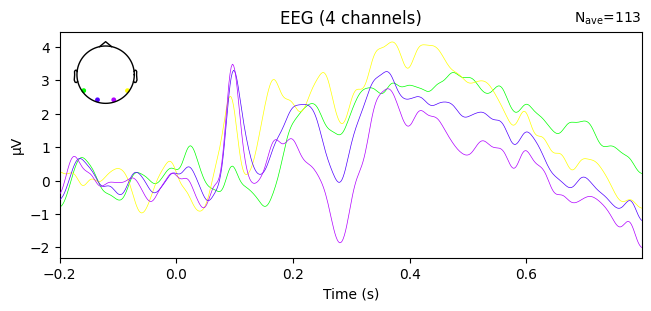

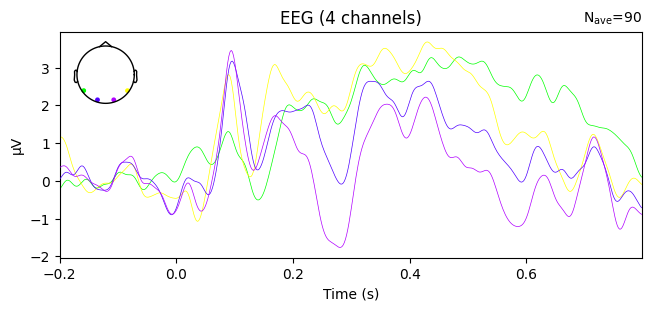

In [50]:
# Plot ERP averaged by perceived emotion (happy vs fear)
evoked_happy_idx = np.where(y == 0)[0]
evoked_fear_idx = np.where(y == 1)[0]

if len(evoked_happy_idx) > 0:
    evoked_happy = epochs_filt[evoked_happy_idx].average()
    fig = evoked_happy.plot(picks=['P7','P8','O1','O2'])
    fig.suptitle('Happy (Perceived)')
    
if len(evoked_fear_idx) > 0:
    evoked_fear = epochs_filt[evoked_fear_idx].average()
    fig = evoked_fear.plot(picks=['P7','P8','O1','O2'])
    fig.suptitle('Fear (Perceived)')

No projector specified for this dataset. Please consider the method self.add_proj.


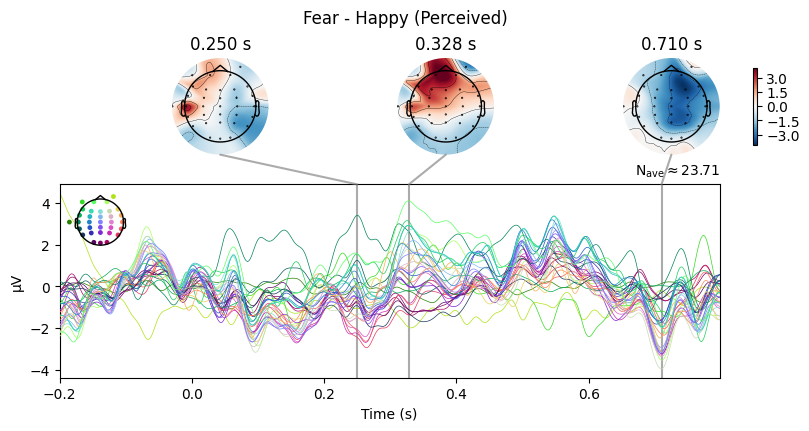

In [48]:
# Difference wave (Fear - Happy)
if len(evoked_happy_idx) > 0 and len(evoked_fear_idx) > 0:
    diff = mne.combine_evoked([evoked_fear, evoked_happy], weights=[1, -1])
    diff.plot_joint(title='Fear - Happy (Perceived)')

NOTE: tfr_morlet() is a legacy function. New code should use .compute_tfr(method="morlet").
NOTE: tfr_morlet() is a legacy function. New code should use .compute_tfr(method="morlet").
Applying baseline correction (mode: logratio)


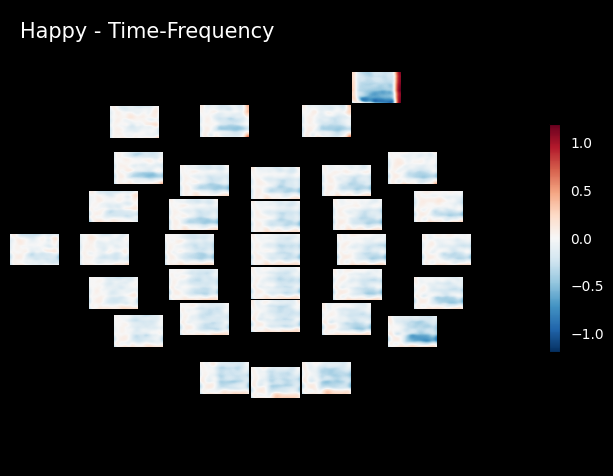

Applying baseline correction (mode: logratio)


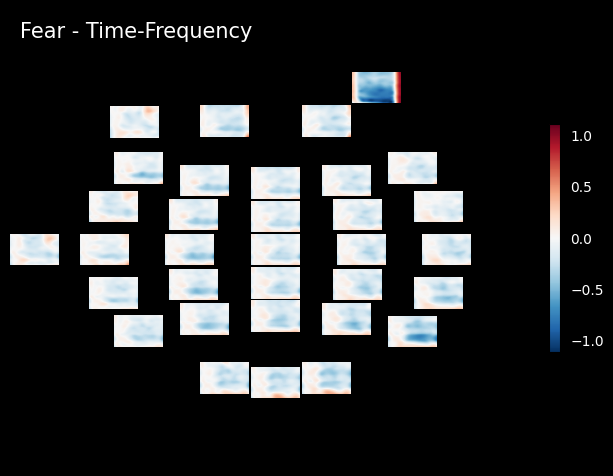

In [49]:
# Time-frequency decomposition by emotion
power_happy = tfr_morlet(
    epochs_filt[evoked_happy_idx],
    freqs=np.arange(4, 31, 1),
    n_cycles=np.arange(4, 31, 1) / 2.0,
    return_itc=False,
    average=True
)

power_fear = tfr_morlet(
    epochs_filt[evoked_fear_idx],
    freqs=np.arange(4, 31, 1),
    n_cycles=np.arange(4, 31, 1) / 2.0,
    return_itc=False,
    average=True
)

if len(evoked_happy_idx) > 0:
    power_happy.plot_topo(title='Happy - Time-Frequency', baseline=(-0.2, 0), mode='logratio')
if len(evoked_fear_idx) > 0:
    power_fear.plot_topo(title='Fear - Time-Frequency', baseline=(-0.2, 0), mode='logratio')

# Advance +
1. Bandpass 0.1–30 Hz & Baseline correction
    * remove slow drift and muscle noise

2. Select channels: 
    * Posterior electrodes for early visual emotion effects
    * Centroparietal for LPP (emotional evaluation)

3. Time window 300–600 ms
    * captures LPP-like activity

4. Feature: trials × (channels × timepoints)

5. Logistic regression with L2

6. Repeated Stratified Cross-Validation
    * 5 fold split is noisy for 28 high ambiguity trials
    * Use balanced acc

7. permutation testing
8. Cross decoding


In [62]:
# Bandpass filter
epochs_filt = epochs.copy().filter(l_freq=0.1, h_freq=30.)

# Baseline correction
epochs_filt.apply_baseline((-0.2, 0))

Setting up band-pass filter from 0.1 - 30 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.10
- Lower transition bandwidth: 0.10 Hz (-6 dB cutoff frequency: 0.05 Hz)
- Upper passband edge: 30.00 Hz
- Upper transition bandwidth: 7.50 Hz (-6 dB cutoff frequency: 33.75 Hz)
- Filter length: 16501 samples (33.002 s)



/var/folders/bj/p5l9vvcj21nfh__sngfwhp3h0000gn/T/ipykernel_77360/1535763080.py:2: RuntimeWarning: filter_length (16501) is longer than the signal (500), distortion is likely. Reduce filter length or filter a longer signal.
  epochs_filt = epochs.copy().filter(l_freq=0.1, h_freq=30.)


Applying baseline correction (mode: mean)


<EpochsEEGLAB | 203 events (all good), -0.2 – 0.798 s (baseline -0.2 – 0 s), ~25.6 MiB, data loaded,
 'B1(31)': 8
 'B2(32)': 9
 'B3(33)': 7
 'B5(45)': 8
 'B2(22)': 9
 'B6(46)': 7
 'B4(24)': 7
 'B7(37)': 8
 'B4(44)': 7
 'B5(35)': 6
 and 18 more events ...>

In [5]:
picks = ['P7','P8','PZ','OZ','CZ']
epochs_sel = epochs_filt.copy().pick(picks)

NameError: name 'epochs_filt' is not defined

In [65]:
epochs_win = epochs_sel.copy().crop(tmin=0.3, tmax=0.6)

In [66]:
X = epochs_win.get_data()          # shape: trials × channels × time
n_trials = X.shape[0]
X = X.reshape(n_trials, -1)        # flatten

print("Feature matrix shape:", X.shape)

Feature matrix shape: (203, 755)


In [67]:
clf = Pipeline([
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(
        penalty='l2',
        C=1,
        solver='liblinear',
        max_iter=1000
    ))
])

In [68]:
def decode_within_ambiguity(X, y, ambiguity, level):

    mask = ambiguity == level
    X_sub = X[mask]
    y_sub = y[mask]

    if len(np.unique(y_sub)) < 2:
        return np.nan

    cv = RepeatedStratifiedKFold(
        n_splits=5,
        n_repeats=20,
        random_state=42
    )

    scores = []

    for train_idx, test_idx in cv.split(X_sub, y_sub):
        clf.fit(X_sub[train_idx], y_sub[train_idx])
        preds = clf.predict(X_sub[test_idx])
        acc = balanced_accuracy_score(y_sub[test_idx], preds)
        scores.append(acc)

    return np.mean(scores), np.std(scores)

In [71]:
levels = ["low","medium","high"]

for level in levels:
    mean_acc, std_acc = decode_within_ambiguity(X, y, ambiguity, level)
    print(f"{level.upper()} → {mean_acc:.3f} ± {std_acc:.3f}")

LOW → 0.576 ± 0.135
MEDIUM → 0.481 ± 0.082
HIGH → 0.541 ± 0.175


In [73]:
from sklearn.model_selection import permutation_test_score

def permutation_test(X, y, ambiguity, level):

    mask = ambiguity == level
    X_sub = X[mask]
    y_sub = y[mask]

    score, perm_scores, pvalue = permutation_test_score(
        clf,
        X_sub,
        y_sub,
        cv=5,
        scoring="balanced_accuracy",
        n_permutations=1000,
        n_jobs=-1
    )

    return score, pvalue

for level in levels:
    score, pval = permutation_test(X, y, ambiguity, level)
    print(f"{level.upper()} → score={score:.3f}, p={pval:.4f}")

LOW → score=0.570, p=0.1958
MEDIUM → score=0.428, p=0.9011
HIGH → score=0.633, p=0.1479


In [75]:
def cross_decode(X, y, ambiguity, train_level, test_level):

    train_mask = ambiguity == train_level
    test_mask  = ambiguity == test_level

    X_train, y_train = X[train_mask], y[train_mask]
    X_test,  y_test  = X[test_mask],  y[test_mask]

    if len(np.unique(y_train)) < 2 or len(np.unique(y_test)) < 2:
        return np.nan

    clf.fit(X_train, y_train)
    preds = clf.predict(X_test)

    return balanced_accuracy_score(y_test, preds)

levels = ["low", "medium", "high"]

for train_level in levels:
    for test_level in levels:
        if train_level == test_level:
            continue

        score = cross_decode(X, y, ambiguity, train_level, test_level)
        print(f"{train_level.upper()} → {test_level.upper()} = {score:.3f}")



LOW → MEDIUM = 0.468
LOW → HIGH = 0.500
MEDIUM → LOW = 0.422
MEDIUM → HIGH = 0.500
HIGH → LOW = 0.476
HIGH → MEDIUM = 0.461


# Loop through

In [8]:
import os
import re
import numpy as np
import scipy.io as sio
import mne
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import balanced_accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from scipy.stats import ttest_rel

In [4]:
def decode_within_ambiguity(X, y, ambiguity, level):

    mask = ambiguity == level
    X_sub = X[mask]
    y_sub = y[mask]

    # Skip if only one class is present or too few samples
    if len(y_sub) < 10 or len(np.unique(y_sub)) < 2:
        return np.nan

    clf = Pipeline([
        ("scaler", StandardScaler()),
        ("logreg", LogisticRegression(
            penalty='l2',
            C=1,
            solver='liblinear',
            max_iter=1000
        ))
    ])

    cv = RepeatedStratifiedKFold(
        n_splits=5,
        n_repeats=20,
        random_state=42
    )

    scores = []

    for train_idx, test_idx in cv.split(X_sub, y_sub):
        # Additional safety check: skip fold if training set doesn't have both classes
        if len(np.unique(y_sub[train_idx])) < 2:
            continue
        
        clf.fit(X_sub[train_idx], y_sub[train_idx])
        preds = clf.predict(X_sub[test_idx])
        acc = balanced_accuracy_score(y_sub[test_idx], preds)
        scores.append(acc)

    # If no valid folds, return nan
    if len(scores) == 0:
        return np.nan

    return np.mean(scores)

In [3]:
mat = sio.loadmat(behavior_mat_path, struct_as_record=False, squeeze_me=True)
eeg_data = mat["eegData"]

In [6]:
subjects = []
low_scores = []
medium_scores = []
high_scores = []

picks = ['P7','P8','PZ','OZ','CZ']  # Define picks here

for sub_id in range(1, 24):

    print(f"\nProcessing Subject {sub_id}")

    # -----------------------
    # Load EEG (with error handling)
    # -----------------------
    file = os.path.join(eeg_path, f"sub{sub_id}ar.set")
    
    if not os.path.exists(file):
        print(f"  ⚠️  File not found: {file}, skipping")
        continue
    
    try:
        epochs = mne.io.read_epochs_eeglab(file, verbose=False)
    except Exception as e:
        print(f"  ⚠️  Error loading EEG: {e}, skipping")
        continue

    # -----------------------
    # Parse morph levels
    # -----------------------
    inv_event_id = {v: k for k, v in epochs.event_id.items()}
    events = epochs.events[:, 2]
    event_names = [inv_event_id[e] for e in events]

    event_codeI = []
    morph_levels = []

    for name in event_names:
        m = re.search(r"\((\d+)(\d)\)", name)
        code_i = int(m.group(1))
        code_l = int(m.group(2))
        event_codeI.append(code_i)
        morph_levels.append(code_l)

    event_codeI = np.array(event_codeI)
    morph_levels = np.array(morph_levels)

    # -----------------------
    # Load behavior for subject
    # -----------------------
    sub_beh = eeg_data[sub_id - 1]
    beh_codeI = np.asarray(sub_beh.codeI).astype(int)
    beh_codeL = np.asarray(sub_beh.codeL).astype(int)
    beh_vResp = np.asarray(sub_beh.vResp).astype(int)

    # -----------------------
    # FIFO matching (handle empty queues)
    # -----------------------
    from collections import defaultdict, deque
    resp_queue = defaultdict(deque)

    for ci, cl, vr in zip(beh_codeI, beh_codeL, beh_vResp):
        resp_queue[(ci, cl)].append(vr)

    matched_vResp = []
    missing = 0
    
    for ci, cl in zip(event_codeI, morph_levels):
        key = (int(ci), int(cl))
        if len(resp_queue[key]) == 0:
            matched_vResp.append(np.nan)
            missing += 1
        else:
            matched_vResp.append(resp_queue[key].popleft())

    matched_vResp = np.asarray(matched_vResp, dtype=float)
    
    # Filter out unmatched trials
    valid_mask = ~np.isnan(matched_vResp)
    epochs = epochs[valid_mask]
    event_codeI = event_codeI[valid_mask]
    morph_levels = morph_levels[valid_mask]
    matched_vResp = matched_vResp[valid_mask].astype(int)
    
    print(f"  Matched trials: {np.sum(valid_mask)}/{len(valid_mask)}, Missing: {missing}")

    # -----------------------
    # Build labels
    # -----------------------
    y = np.zeros(len(matched_vResp), dtype=int)
    y[matched_vResp == 1] = 1  # fear=1, happy=0

    # -----------------------
    # Ambiguity binning
    # -----------------------
    def ambiguity_bin(code):
        if code in [1,7]:
            return "low"
        elif code in [2,3,5,6]:
            return "medium"
        elif code == 4:
            return "high"

    ambiguity = np.array([ambiguity_bin(c) for c in morph_levels])

    # -----------------------
    # Preprocessing
    # -----------------------
    epochs = epochs.filter(0.1, 30., verbose=False)
    epochs.apply_baseline((-0.2, 0), verbose=False)

    epochs = epochs.pick(picks, verbose=False)

    epochs = epochs.crop(0.3, 0.6, verbose=False)

    X = epochs.get_data()
    X = X.reshape(len(X), -1)

    # -----------------------
    # Decode
    # -----------------------
    low_acc = decode_within_ambiguity(X, y, ambiguity, "low")
    med_acc = decode_within_ambiguity(X, y, ambiguity, "medium")
    high_acc = decode_within_ambiguity(X, y, ambiguity, "high")

    subjects.append(sub_id)
    low_scores.append(low_acc)
    medium_scores.append(med_acc)
    high_scores.append(high_acc)

    print(f"  LOW: {low_acc:.3f}, MEDIUM: {med_acc:.3f}, HIGH: {high_acc:.3f}")


Processing Subject 1
  Matched trials: 203/203, Missing: 0


/var/folders/bj/p5l9vvcj21nfh__sngfwhp3h0000gn/T/ipykernel_92790/852282325.py:108: RuntimeWarning: filter_length (16501) is longer than the signal (500), distortion is likely. Reduce filter length or filter a longer signal.
  epochs = epochs.filter(0.1, 30., verbose=False)


  LOW: 0.576, MEDIUM: 0.481, HIGH: 0.541

Processing Subject 2
  Matched trials: 202/203, Missing: 1


/var/folders/bj/p5l9vvcj21nfh__sngfwhp3h0000gn/T/ipykernel_92790/852282325.py:108: RuntimeWarning: filter_length (16501) is longer than the signal (500), distortion is likely. Reduce filter length or filter a longer signal.
  epochs = epochs.filter(0.1, 30., verbose=False)


  LOW: 0.454, MEDIUM: 0.486, HIGH: 0.420

Processing Subject 3
  Matched trials: 187/187, Missing: 0


...

  LOW: 0.521, MEDIUM: 0.484, HIGH: 0.431

Processing Subject 21
  Matched trials: 85/85, Missing: 0


/var/folders/bj/p5l9vvcj21nfh__sngfwhp3h0000gn/T/ipykernel_92790/852282325.py:108: RuntimeWarning: filter_length (16501) is longer than the signal (500), distortion is likely. Reduce filter length or filter a longer signal.
  epochs = epochs.filter(0.1, 30., verbose=False)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/Library/Frameworks/Python.framewor

  LOW: 0.414, MEDIUM: 0.553, HIGH: 0.410

Processing Subject 22
  Matched trials: 209/209, Missing: 0
  LOW: 0.567, MEDIUM: 0.533, HIGH: 0.525

Processing Subject 23
  Matched trials: 154/154, Missing: 0


/var/folders/bj/p5l9vvcj21nfh__sngfwhp3h0000gn/T/ipykernel_92790/852282325.py:108: RuntimeWarning: filter_length (16501) is longer than the signal (500), distortion is likely. Reduce filter length or filter a longer signal.
  epochs = epochs.filter(0.1, 30., verbose=False)


  LOW: 0.448, MEDIUM: 0.574, HIGH: 0.625


In [9]:
results_df = pd.DataFrame({
    "subject": subjects,
    "low": low_scores,
    "medium": medium_scores,
    "high": high_scores
})

print(results_df.describe())

         subject        low     medium       high
count  22.000000  22.000000  22.000000  21.000000
mean   12.227273   0.538423   0.503850   0.504440
std     6.851707   0.080615   0.041879   0.113904
min     1.000000   0.391667   0.401513   0.311667
25%     6.500000   0.478375   0.481455   0.420000
50%    12.500000   0.561339   0.496028   0.525500
75%    17.750000   0.586682   0.537191   0.595000
max    23.000000   0.686000   0.577004   0.720000


In [10]:
t_low_high, p_low_high = ttest_rel(low_scores, high_scores)
t_low_med, p_low_med = ttest_rel(low_scores, medium_scores)
t_med_high, p_med_high = ttest_rel(medium_scores, high_scores)

print("\nGroup-Level Statistics:")
print(f"Low > High: t={t_low_high:.3f}, p={p_low_high:.4f}")
print(f"Low > Medium: t={t_low_med:.3f}, p={p_low_med:.4f}")
print(f"Medium > High: t={t_med_high:.3f}, p={p_med_high:.4f}")


Group-Level Statistics:
Low > High: t=nan, p=nan
Low > Medium: t=1.840, p=0.0800
Medium > High: t=nan, p=nan
